In [3]:
# 1. Imports and Configuration
from pathlib import Path
import json
import warnings
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    RandomizedSearchCV,
    cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
)

from scipy.stats import norm

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is required. Run: python -m pip install xgboost"
    ) from exc

RANDOM_STATE = 42
N_SPLITS = 5
N_REPEATS = 3
SEARCH_ITERATIONS = 3
SEARCH_CV_SPLITS = 3

PROJECT_DIR = Path.cwd()
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR = PROJECT_DIR / "data"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("default")
pd.set_option("display.max_columns", 100)

print("FinResilience AI - Notebook 2")
print("Project:", PROJECT_DIR.resolve())
print("Random seed:", RANDOM_STATE)

FinResilience AI - Notebook 2
Project: C:\mini_project
Random seed: 42


In [6]:
feature_path = ARTIFACT_DIR / "home_credit_feature_table.csv"
train_path = ARTIFACT_DIR / "home_credit_train.csv"
test_path = ARTIFACT_DIR / "home_credit_test_LOCKED.csv"
manifest_path = ARTIFACT_DIR / "home_credit_feature_groups.json"

for path in [feature_path, train_path, test_path, manifest_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required Notebook 1 artifact missing: {path}\n"
            "Run Notebook 1 completely before continuing."
        )

feature_table = pd.read_csv(feature_path)
train_saved = pd.read_csv(train_path)
test_locked = pd.read_csv(test_path)

with open(manifest_path, "r", encoding="utf-8") as file:
    manifest = json.load(file)

GROUP_A = manifest["group_a_features"]
GROUP_B = manifest["group_b_features"]

ID_COL = "SK_ID_CURR"
TARGET_COL = "TARGET"

for name, data in [
    ("feature table", feature_table),
    ("training set", train_saved),
    ("locked test set", test_locked),
]:
    if ID_COL not in data.columns or TARGET_COL not in data.columns:
        raise ValueError(f"{name} is missing {ID_COL} or {TARGET_COL}.")

if set(train_saved[ID_COL]) & set(test_locked[ID_COL]):
    raise ValueError("Train and test applicant IDs overlap.")

if feature_table[ID_COL].duplicated().any():
    raise ValueError("Duplicate applicant IDs in feature table.")

if not set(train_saved[ID_COL]).isdisjoint(set(test_locked[ID_COL])):
    raise ValueError("Applicant leakage detected across train/test split.")

# Remove accidental duplicates and restrict features to available columns.
GROUP_A = list(dict.fromkeys(
    c for c in GROUP_A
    if c in train_saved.columns and c not in [ID_COL, TARGET_COL]
))
GROUP_B = list(dict.fromkeys(
    c for c in GROUP_B
    if c in train_saved.columns and c not in [ID_COL, TARGET_COL]
))

if not GROUP_A:
    raise ValueError("Group A feature list is empty.")
if not GROUP_B:
    raise ValueError("Group B feature list is empty.")

# Group B is the added behavioural set; it must include Group A plus behavioural features.
# The model comparison uses A-only and A-plus-B, avoiding an unfair comparison.
BEHAVIOURAL_FEATURES = [
    c for c in GROUP_B if c not in GROUP_A
]
GROUP_B_FULL = GROUP_A + BEHAVIOURAL_FEATURES

if not BEHAVIOURAL_FEATURES:
    raise ValueError(
        "No additional behavioural features were found. "
        "Check the feature manifest from Notebook 1."
    )

print("Training rows:", len(train_saved))
print("Locked test rows:", len(test_locked))
print("Group A feature count:", len(GROUP_A))
print("Additional behavioural feature count:", len(BEHAVIOURAL_FEATURES))
print("Group B total feature count:", len(GROUP_B_FULL))
print("Target distribution in training:")
display(train_saved[TARGET_COL].value_counts(normalize=True).sort_index())

Training rows: 246008
Locked test rows: 61503
Group A feature count: 25
Additional behavioural feature count: 32
Group B total feature count: 57
Target distribution in training:


TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

In [7]:

train_core, calibration_validation = train_test_split(
    train_saved,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=train_saved[TARGET_COL],
)

y_core = train_core[TARGET_COL].astype(int)
y_validation = calibration_validation[TARGET_COL].astype(int)
y_test = test_locked[TARGET_COL].astype(int)

X_core_A = train_core[GROUP_A].copy()
X_core_B = train_core[GROUP_B_FULL].copy()

X_validation_A = calibration_validation[GROUP_A].copy()
X_validation_B = calibration_validation[GROUP_B_FULL].copy()

X_test_A = test_locked[GROUP_A].copy()
X_test_B = test_locked[GROUP_B_FULL].copy()

print("Model-development rows:", len(train_core))
print("Threshold-validation rows:", len(calibration_validation))
print("Locked test rows:", len(test_locked))
print("Positive rate in model-development data:", round(y_core.mean(), 4))
print("Positive rate in threshold-validation data:", round(y_validation.mean(), 4))

Model-development rows: 209106
Threshold-validation rows: 36902
Locked test rows: 61503
Positive rate in model-development data: 0.0807
Positive rate in threshold-validation data: 0.0807


In [8]:

def make_preprocessor(X, scale_numeric=False):
    numeric_features = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_features = [
        c for c in X.columns if c not in numeric_features
    ]

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])


def make_model_pipeline(model_name, X):
    scale_numeric = model_name == "Logistic Regression"

    preprocessor = make_preprocessor(
        X,
        scale_numeric=scale_numeric
    )

    if model_name == "Logistic Regression":
        estimator = LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            solver="liblinear",
        )

    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    elif model_name == "XGBoost":
        estimator = XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=1,
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator),
    ])


MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
]

PARAMETER_DISTRIBUTIONS = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 10.0],
    },
    "Random Forest": {
        "model__max_depth": [8, 14, None],
        "model__min_samples_leaf": [2, 10, 25],
        "model__max_features": ["sqrt", 0.5],
    },
    "XGBoost": {
        "model__max_depth": [3, 5, 7],
        "model__learning_rate": [0.03, 0.08, 0.15],
        "model__min_child_weight": [1, 5],
        "model__subsample": [0.8, 1.0],
    },
}

print("Model definitions created.")

Model definitions created.


In [9]:
dummy = DummyClassifier(strategy="prior")
dummy.fit(np.zeros((len(y_core), 1)), y_core)

dummy_validation_probability = dummy.predict_proba(
    np.zeros((len(y_validation), 1))
)[:, 1]

dummy_metrics = {
    "model": "Dummy baseline",
    "feature_group": "None",
    "PR_AUC": average_precision_score(
        y_validation, dummy_validation_probability
    ),
    "ROC_AUC": roc_auc_score(
        y_validation, dummy_validation_probability
    ),
}

display(pd.DataFrame([dummy_metrics]))

,model,feature_group,PR_AUC,ROC_AUC
0,Dummy baseline,None,0.080727,0.5


In [10]:
from sklearn.model_selection import ParameterSampler

FEATURE_GROUPS = {
    "A_conventional": GROUP_A,
    "B_conventional_plus_behavioural": GROUP_B_FULL,
}

tuned_models = {}
cv_results = []
search_results = []

for group_name, feature_columns in FEATURE_GROUPS.items():
    X = train_core[feature_columns].copy()

    for model_name in MODEL_NAMES:
        print(f"\nTuning: {model_name} | {group_name}")

        pipeline = make_model_pipeline(model_name, X)

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=PARAMETER_DISTRIBUTIONS[model_name],
            n_iter=SEARCH_ITERATIONS,
            scoring="average_precision",
            cv=StratifiedKFold(
                n_splits=SEARCH_CV_SPLITS,
                shuffle=True,
                random_state=RANDOM_STATE,
            ),
            random_state=RANDOM_STATE,
            n_jobs=1,
            refit=True,
            error_score="raise",
            return_train_score=False,
        )

        search.fit(X, y_core)

        best_model = search.best_estimator_
        tuned_models[(group_name, model_name)] = best_model

        search_results.append({
            "feature_group": group_name,
            "model": model_name,
            "best_cv_PR_AUC": search.best_score_,
            "best_parameters": json.dumps(search.best_params_),
            "search_iterations": SEARCH_ITERATIONS,
        })

        repeated_cv = RepeatedStratifiedKFold(
            n_splits=N_SPLITS,
            n_repeats=N_REPEATS,
            random_state=RANDOM_STATE,
        )

        fold_scores = cross_validate(
            best_model,
            X,
            y_core,
            cv=repeated_cv,
            scoring={
                "PR_AUC": "average_precision",
                "ROC_AUC": "roc_auc",
                "F1": "f1",
                "Precision": "precision",
                "Recall": "recall",
            },
            n_jobs=1,
            return_train_score=False,
            error_score="raise",
        )

        for fold_index in range(len(fold_scores["test_PR_AUC"])):
            cv_results.append({
                "feature_group": group_name,
                "model": model_name,
                "fold": fold_index + 1,
                "PR_AUC": fold_scores["test_PR_AUC"][fold_index],
                "ROC_AUC": fold_scores["test_ROC_AUC"][fold_index],
                "F1": fold_scores["test_F1"][fold_index],
                "Precision": fold_scores["test_Precision"][fold_index],
                "Recall": fold_scores["test_Recall"][fold_index],
            })

        del search, fold_scores
        gc.collect()

search_results_df = pd.DataFrame(search_results)
cv_results_df = pd.DataFrame(cv_results)

search_results_df.to_csv(
    RESULTS_DIR / "hyperparameter_search.csv",
    index=False,
)
cv_results_df.to_csv(
    RESULTS_DIR / "repeated_cv_fold_results.csv",
    index=False,
)

display(search_results_df)


Tuning: Logistic Regression | A_conventional

Tuning: Random Forest | A_conventional

Tuning: XGBoost | A_conventional


c:\mini_project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\mini_project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\mini_project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



Tuning: Logistic Regression | B_conventional_plus_behavioural

Tuning: Random Forest | B_conventional_plus_behavioural

Tuning: XGBoost | B_conventional_plus_behavioural


,feature_group,model,best_cv_PR_AUC,best_parameters,search_iterations
0,A_conventional,Logistic Regression,0.145886,"{""model__C"": 0.1}",3
1,A_conventional,Random Forest,0.149736,"{""model__min_samples_leaf"": 25, ""model__max_fe...",3
2,A_conventional,XGBoost,0.159213,"{""model__subsample"": 0.8, ""model__min_child_we...",3
3,B_conventional_plus_behavioural,Logistic Regression,0.184539,"{""model__C"": 0.1}",3
4,B_conventional_plus_behavioural,Random Forest,0.180775,"{""model__min_samples_leaf"": 25, ""model__max_fe...",3
5,B_conventional_plus_behavioural,XGBoost,0.204398,"{""model__subsample"": 0.8, ""model__min_child_we...",3


,feature_group,model,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,F1_mean,Precision_mean,Recall_mean
5,B_conventional_plus_behavioural,XGBoost,0.203404,0.002989,0.723764,0.014366,0.520223,0.007286
3,B_conventional_plus_behavioural,Logistic Regression,0.184761,0.002951,0.706387,0.231802,0.141017,0.650771
4,B_conventional_plus_behavioural,Random Forest,0.181727,0.004056,0.703742,0.251113,0.169762,0.482219
2,A_conventional,XGBoost,0.161545,0.004020,0.678211,0.000592,0.544444,0.000296
1,A_conventional,Random Forest,0.150768,0.003063,0.662048,0.216376,0.136833,0.516853
0,A_conventional,Logistic Regression,0.145867,0.002813,0.657512,0.203224,0.121236,0.627767


,model,A_mean_PR_AUC,B_mean_PR_AUC,mean_difference_B_minus_A,wilcoxon_statistic,wilcoxon_p_value
0,Logistic Regression,0.145867,0.184761,0.038894,0.0,0.000061
1,Random Forest,0.150768,0.181727,0.030959,0.0,0.000061
2,XGBoost,0.161545,0.203404,0.041860,0.0,0.000061


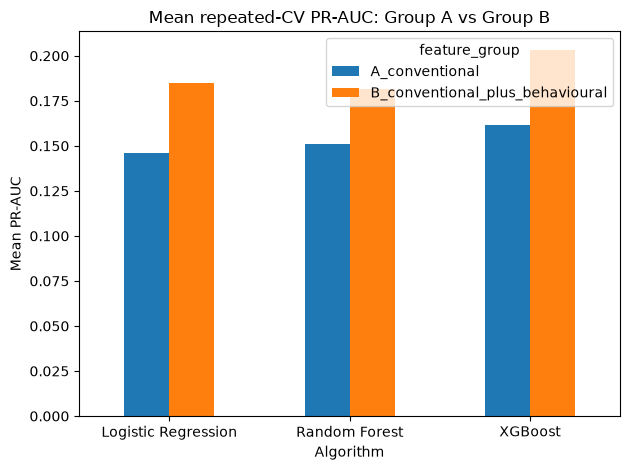

In [12]:
cv_summary = (
    cv_results_df
    .groupby(["feature_group", "model"])
    .agg(
        PR_AUC_mean=("PR_AUC", "mean"),
        PR_AUC_std=("PR_AUC", "std"),
        ROC_AUC_mean=("ROC_AUC", "mean"),
        F1_mean=("F1", "mean"),
        Precision_mean=("Precision", "mean"),
        Recall_mean=("Recall", "mean"),
    )
    .reset_index()
)

display(cv_summary.sort_values("PR_AUC_mean", ascending=False))

cv_summary.to_csv(
    RESULTS_DIR / "cross_validation_summary.csv",
    index=False,
)

paired_cv_tests = []

for model_name in MODEL_NAMES:
    a = cv_results_df[
        (cv_results_df["feature_group"] == "A_conventional")
        & (cv_results_df["model"] == model_name)
    ].sort_values("fold")["PR_AUC"].to_numpy()

    b = cv_results_df[
        (cv_results_df["feature_group"] == "B_conventional_plus_behavioural")
        & (cv_results_df["model"] == model_name)
    ].sort_values("fold")["PR_AUC"].to_numpy()

    if len(a) != len(b):
        raise ValueError("A/B cross-validation fold counts do not match.")

    differences = b - a

    # The Wilcoxon test is applied to paired fold scores.
    # With repeated CV, fold scores are correlated, so this is supportive
    # evidence, not a definitive independent-sample significance test.
    if np.allclose(differences, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            b, a, alternative="two-sided"
        )

    paired_cv_tests.append({
        "model": model_name,
        "A_mean_PR_AUC": float(a.mean()),
        "B_mean_PR_AUC": float(b.mean()),
        "mean_difference_B_minus_A": float(differences.mean()),
        "wilcoxon_statistic": float(statistic),
        "wilcoxon_p_value": float(p_value),
    })

paired_cv_tests_df = pd.DataFrame(paired_cv_tests)
display(paired_cv_tests_df)

paired_cv_tests_df.to_csv(
    RESULTS_DIR / "paired_cv_feature_group_tests.csv",
    index=False,
)

ax = cv_summary.pivot(
    index="model",
    columns="feature_group",
    values="PR_AUC_mean",
).plot(kind="bar", rot=0)

ax.set_title("Mean repeated-CV PR-AUC: Group A vs Group B")
ax.set_ylabel("Mean PR-AUC")
ax.set_xlabel("Algorithm")
plt.tight_layout()
plt.show()

In [13]:
def choose_f1_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    if len(thresholds) == 0:
        return 0.5

    # The last precision/recall point has no corresponding threshold.
    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = int(np.nanargmax(f1_values))
    return float(thresholds[best_index])


calibrated_models = {}
selected_thresholds = {}
validation_results = []

for group_name, feature_columns in FEATURE_GROUPS.items():
    X_core = train_core[feature_columns]
    X_validation = calibration_validation[feature_columns]

    for model_name in MODEL_NAMES:
        print(f"Calibrating: {model_name} | {group_name}")

        base_model = tuned_models[(group_name, model_name)]

        calibrated_model = CalibratedClassifierCV(
            estimator=clone(base_model),
            method="sigmoid",
            cv=StratifiedKFold(
                n_splits=3,
                shuffle=True,
                random_state=RANDOM_STATE,
            ),
        )

        calibrated_model.fit(X_core, y_core)

        validation_probability = calibrated_model.predict_proba(
            X_validation
        )[:, 1]

        threshold = choose_f1_threshold(
            y_validation,
            validation_probability,
        )

        validation_results.append({
            "feature_group": group_name,
            "model": model_name,
            "validation_PR_AUC": average_precision_score(
                y_validation, validation_probability
            ),
            "validation_ROC_AUC": roc_auc_score(
                y_validation, validation_probability
            ),
            "validation_Brier": brier_score_loss(
                y_validation, validation_probability
            ),
            "selected_threshold": threshold,
        })

        calibrated_models[(group_name, model_name)] = calibrated_model
        selected_thresholds[(group_name, model_name)] = threshold

validation_results_df = pd.DataFrame(validation_results)
display(validation_results_df)

validation_results_df.to_csv(
    RESULTS_DIR / "calibration_validation_results.csv",
    index=False,
)

Calibrating: Logistic Regression | A_conventional
Calibrating: Random Forest | A_conventional
Calibrating: XGBoost | A_conventional
Calibrating: Logistic Regression | B_conventional_plus_behavioural
Calibrating: Random Forest | B_conventional_plus_behavioural
Calibrating: XGBoost | B_conventional_plus_behavioural


,feature_group,model,validation_PR_AUC,validation_ROC_AUC,validation_Brier,selected_threshold
0,A_conventional,Logistic Regression,0.147338,0.659846,0.072233,0.103463
1,A_conventional,Random Forest,0.154275,0.660204,0.072083,0.116810
2,A_conventional,XGBoost,0.165344,0.674444,0.071726,0.108642
3,B_conventional_plus_behavioural,Logistic Regression,0.179153,0.705569,0.070792,0.134290
4,B_conventional_plus_behavioural,Random Forest,0.176651,0.702579,0.070925,0.101414
5,B_conventional_plus_behavioural,XGBoost,0.203056,0.721871,0.070467,0.105875


In [14]:
def calculate_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "PR_AUC": average_precision_score(y_true, probabilities),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "Log_Loss": log_loss(
            y_true, probabilities, labels=[0, 1]
        ),
        "Threshold": threshold,
    }


test_results = []
test_probabilities = {}

for group_name, feature_columns in FEATURE_GROUPS.items():
    X_test = test_locked[feature_columns]

    for model_name in MODEL_NAMES:
        key = (group_name, model_name)
        model = calibrated_models[key]
        threshold = selected_thresholds[key]

        probabilities = model.predict_proba(X_test)[:, 1]
        test_probabilities[key] = probabilities

        metrics = calculate_metrics(
            y_test,
            probabilities,
            threshold,
        )

        test_results.append({
            "feature_group": group_name,
            "model": model_name,
            **metrics,
        })

test_results_df = pd.DataFrame(test_results)
display(test_results_df.sort_values("PR_AUC", ascending=False))

test_results_df.to_csv(
    RESULTS_DIR / "final_locked_test_results.csv",
    index=False,
)

# Confusion matrix and classification report for each final model.
for group_name, feature_columns in FEATURE_GROUPS.items():
    for model_name in MODEL_NAMES:
        key = (group_name, model_name)
        predictions = (
            test_probabilities[key] >= selected_thresholds[key]
        ).astype(int)

        print("\n", group_name, "|", model_name)
        print("Confusion matrix:")
        print(confusion_matrix(y_test, predictions))
        print(classification_report(
            y_test, predictions, zero_division=0
        ))

,feature_group,model,PR_AUC,ROC_AUC,Precision,Recall,F1,Brier_Score,Log_Loss,Threshold
5,B_conventional_plus_behavioural,XGBoost,0.206222,0.724958,0.211433,0.405237,0.277881,0.070255,0.258312,0.105875
3,B_conventional_plus_behavioural,Logistic Regression,0.184813,0.706611,0.199489,0.361732,0.257159,0.070577,0.259344,0.134290
4,B_conventional_plus_behavioural,Random Forest,0.182567,0.706685,0.163932,0.519235,0.249190,0.070607,0.259474,0.101414
2,A_conventional,XGBoost,0.166549,0.678961,0.178500,0.343807,0.234994,0.071669,0.265719,0.108642
1,A_conventional,Random Forest,0.155214,0.664446,0.159043,0.380262,0.224281,0.071982,0.267218,0.116810
0,A_conventional,Logistic Regression,0.145376,0.657519,0.142092,0.448741,0.215839,0.072299,0.268804,0.103463



 A_conventional | Logistic Regression
Confusion matrix:
[[43086 13452]
 [ 2737  2228]]
              precision    recall  f1-score   support

           0       0.94      0.76      0.84     56538
           1       0.14      0.45      0.22      4965

    accuracy                           0.74     61503
   macro avg       0.54      0.61      0.53     61503
weighted avg       0.88      0.74      0.79     61503


 A_conventional | Random Forest
Confusion matrix:
[[46555  9983]
 [ 3077  1888]]
              precision    recall  f1-score   support

           0       0.94      0.82      0.88     56538
           1       0.16      0.38      0.22      4965

    accuracy                           0.79     61503
   macro avg       0.55      0.60      0.55     61503
weighted avg       0.88      0.79      0.82     61503


 A_conventional | XGBoost
Confusion matrix:
[[48682  7856]
 [ 3258  1707]]
              precision    recall  f1-score   support

           0       0.94      0.86      0.90  

In [15]:
def bootstrap_auc_intervals(
    y_true,
    probabilities,
    n_bootstrap=1000,
    random_state=RANDOM_STATE,
):
    rng = np.random.default_rng(random_state)
    y_array = np.asarray(y_true)
    p_array = np.asarray(probabilities)

    pr_scores = []
    roc_scores = []
    n = len(y_array)

    for _ in range(n_bootstrap):
        indices = rng.integers(0, n, n)
        y_sample = y_array[indices]
        p_sample = p_array[indices]

        # A bootstrap sample must contain both classes for ROC-AUC.
        if len(np.unique(y_sample)) < 2:
            continue

        pr_scores.append(
            average_precision_score(y_sample, p_sample)
        )
        roc_scores.append(
            roc_auc_score(y_sample, p_sample)
        )

    return {
        "PR_AUC_CI_low": float(np.percentile(pr_scores, 2.5)),
        "PR_AUC_CI_high": float(np.percentile(pr_scores, 97.5)),
        "ROC_AUC_CI_low": float(np.percentile(roc_scores, 2.5)),
        "ROC_AUC_CI_high": float(np.percentile(roc_scores, 97.5)),
        "bootstrap_samples_used": len(pr_scores),
    }


confidence_intervals = []

for key, probabilities in test_probabilities.items():
    group_name, model_name = key

    ci = bootstrap_auc_intervals(y_test, probabilities)

    confidence_intervals.append({
        "feature_group": group_name,
        "model": model_name,
        **ci,
    })

confidence_intervals_df = pd.DataFrame(confidence_intervals)
display(confidence_intervals_df)

confidence_intervals_df.to_csv(
    RESULTS_DIR / "bootstrap_confidence_intervals.csv",
    index=False,
)

,feature_group,model,PR_AUC_CI_low,PR_AUC_CI_high,ROC_AUC_CI_low,ROC_AUC_CI_high,bootstrap_samples_used
0,A_conventional,Logistic Regression,0.139433,0.152510,0.650114,0.666068,1000
1,A_conventional,Random Forest,0.148482,0.163033,0.657293,0.672712,1000
2,A_conventional,XGBoost,0.159552,0.174838,0.671239,0.687462,1000
3,B_conventional_plus_behavioural,Logistic Regression,0.176271,0.194908,0.698823,0.715065,1000
4,B_conventional_plus_behavioural,Random Forest,0.174273,0.191487,0.699471,0.714888,1000
5,B_conventional_plus_behavioural,XGBoost,0.196481,0.216828,0.717695,0.733347,1000


In [16]:
def compute_midrank(values):
    values = np.asarray(values)
    order = np.argsort(values)
    sorted_values = values[order]
    ranks = np.zeros(len(values), dtype=float)

    i = 0
    while i < len(values):
        j = i
        while j < len(values) and sorted_values[j] == sorted_values[i]:
            j += 1

        ranks[order[i:j]] = 0.5 * (i + j - 1) + 1
        i = j

    return ranks


def fast_delong(predictions_sorted, n_positive):
    m = n_positive
    n = predictions_sorted.shape[1] - m

    positive_scores = predictions_sorted[:, :m]
    negative_scores = predictions_sorted[:, m:]

    tx = np.vstack([
        compute_midrank(row) for row in positive_scores
    ])
    ty = np.vstack([
        compute_midrank(row) for row in negative_scores
    ])
    tz = np.vstack([
        compute_midrank(row) for row in predictions_sorted
    ])

    aucs = (
        tz[:, :m].sum(axis=1) / m - (m + 1) / 2
    ) / n

    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m

    cov01 = np.atleast_2d(np.cov(v01))
    cov10 = np.atleast_2d(np.cov(v10))

    covariance = cov01 / m + cov10 / n

    return aucs, covariance


def delong_test(y_true, scores_a, scores_b):
    y_true = np.asarray(y_true).astype(int)
    scores = np.vstack([scores_a, scores_b])

    # DeLong expects positive examples first.
    order = np.argsort(-y_true)
    sorted_scores = scores[:, order]

    n_positive = int(y_true.sum())
    n_negative = len(y_true) - n_positive

    if n_positive == 0 or n_negative == 0:
        raise ValueError("DeLong test requires both target classes.")

    aucs, covariance = fast_delong(
        sorted_scores, n_positive
    )

    difference = aucs[0] - aucs[1]
    variance = (
        covariance[0, 0]
        + covariance[1, 1]
        - 2 * covariance[0, 1]
    )

    if variance <= 0:
        return {
            "A_ROC_AUC": float(aucs[0]),
            "B_ROC_AUC": float(aucs[1]),
            "difference_A_minus_B": float(difference),
            "z_statistic": np.nan,
            "p_value": np.nan,
        }

    z_statistic = difference / np.sqrt(variance)
    p_value = 2 * norm.sf(abs(z_statistic))

    return {
        "A_ROC_AUC": float(aucs[0]),
        "B_ROC_AUC": float(aucs[1]),
        "difference_A_minus_B": float(difference),
        "z_statistic": float(z_statistic),
        "p_value": float(p_value),
    }


delong_results = []

for model_name in MODEL_NAMES:
    result = delong_test(
        y_test,
        test_probabilities[("A_conventional", model_name)],
        test_probabilities[(
            "B_conventional_plus_behavioural", model_name
        )],
    )

    delong_results.append({
        "model": model_name,
        **result,
    })

delong_results_df = pd.DataFrame(delong_results)
display(delong_results_df)

delong_results_df.to_csv(
    RESULTS_DIR / "delong_roc_auc_tests.csv",
    index=False,
)

,model,A_ROC_AUC,B_ROC_AUC,difference_A_minus_B,z_statistic,p_value
0,Logistic Regression,0.657519,0.706611,-0.049092,-16.947503,2.008014e-64
1,Random Forest,0.664446,0.706685,-0.042239,-13.560339,6.881729e-42
2,XGBoost,0.678961,0.724958,-0.045996,-15.350647,3.506721e-53


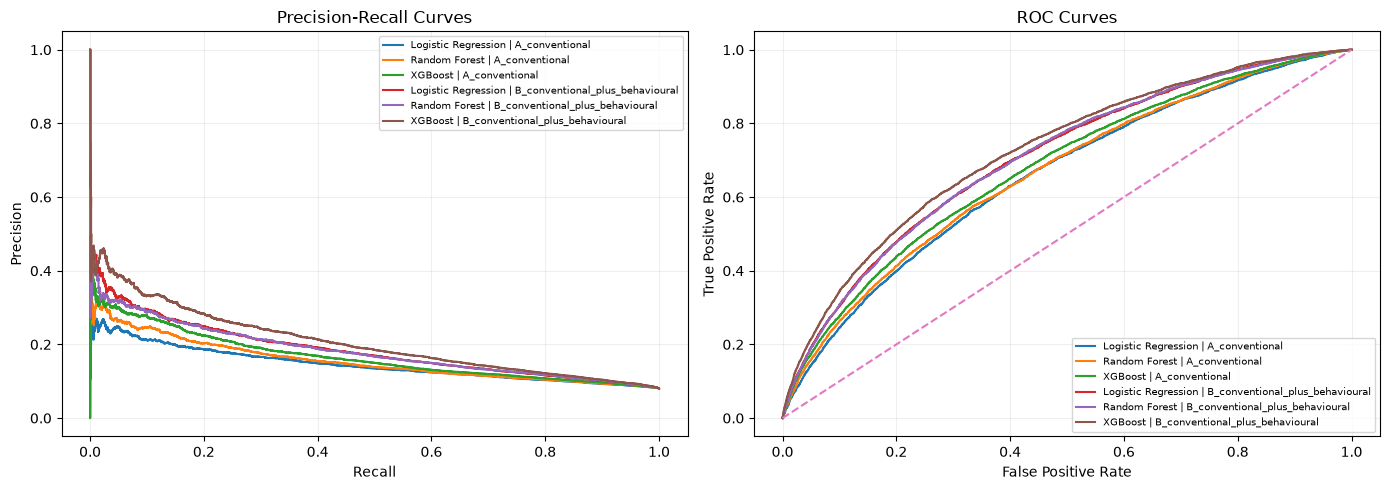

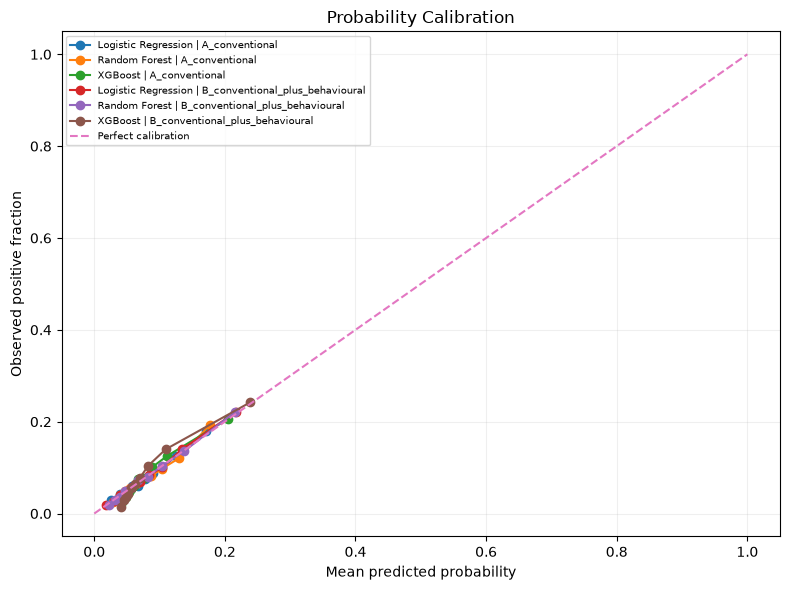

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for key, probabilities in test_probabilities.items():
    group_name, model_name = key
    label = f"{model_name} | {group_name}"

    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )
    axes[0].plot(recall, precision, label=label)

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    axes[1].plot(fpr, tpr, label=label)

axes[0].set_title("Precision-Recall Curves")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")

axes[1].plot([0, 1], [0, 1], linestyle="--")
axes[1].set_title("ROC Curves")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "roc_pr_curves.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


fig, ax = plt.subplots(figsize=(8, 6))

for key, probabilities in test_probabilities.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile",
    )
    ax.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=f"{key[1]} | {key[0]}",
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.set_title("Probability Calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed positive fraction")
ax.legend(fontsize=7)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "calibration_curves.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [18]:
def identify_feature_family(feature_name):
    name = feature_name.upper()

    if name.startswith("INST_") or "INSTALLMENT" in name:
        return "Installment behaviour"

    if name.startswith("CC_") or "CREDIT_CARD" in name:
        return "Credit-card behaviour"

    if name.startswith("BURO_") or "BUREAU" in name:
        return "Bureau behaviour"

    if name.startswith("HAS_"):
        return "History availability"

    return "Other behavioural features"


behavioural_families = {}
for feature in BEHAVIOURAL_FEATURES:
    family = identify_feature_family(feature)
    behavioural_families.setdefault(family, []).append(feature)

print("Behavioural feature families:")
for family, features in behavioural_families.items():
    print(f"{family}: {len(features)} features")


# Select the algorithm with the best Group B mean repeated-CV PR-AUC.
group_b_cv = cv_summary[
    cv_summary["feature_group"] == "B_conventional_plus_behavioural"
]
selected_ablation_model = group_b_cv.sort_values(
    "PR_AUC_mean", ascending=False
).iloc[0]["model"]

print("Ablation model selected from CV:", selected_ablation_model)

ablation_results = []

full_columns = GROUP_B_FULL
full_model = tuned_models[(
    "B_conventional_plus_behavioural",
    selected_ablation_model,
)]

full_validation_model = clone(full_model)
full_validation_model.fit(
    train_core[full_columns], y_core
)

full_validation_prob = full_validation_model.predict_proba(
    calibration_validation[full_columns]
)[:, 1]

ablation_results.append({
    "condition": "All Group B features",
    "removed_family": "None",
    "validation_PR_AUC": average_precision_score(
        y_validation, full_validation_prob
    ),
})

for family, family_features in behavioural_families.items():
    remaining_columns = [
        c for c in full_columns if c not in family_features
    ]

    ablated_model = make_model_pipeline(
        selected_ablation_model,
        train_core[remaining_columns],
    )

    # Keep the best hyperparameters from the full Group B search.
    best_params = tuned_models[
        ("B_conventional_plus_behavioural", selected_ablation_model)
    ].get_params()

    transferable_params = {
        key: value
        for key, value in best_params.items()
        if key.startswith("model__")
    }

    ablated_model.set_params(**transferable_params)
    ablated_model.fit(train_core[remaining_columns], y_core)

    probabilities = ablated_model.predict_proba(
        calibration_validation[remaining_columns]
    )[:, 1]

    ablation_results.append({
        "condition": f"Without {family}",
        "removed_family": family,
        "validation_PR_AUC": average_precision_score(
            y_validation, probabilities
        ),
    })

ablation_df = pd.DataFrame(ablation_results)
display(ablation_df)

ablation_df.to_csv(
    RESULTS_DIR / "feature_family_ablation.csv",
    index=False,
)

Behavioural feature families:
Other behavioural features: 2 features
Installment behaviour: 8 features
Credit-card behaviour: 7 features
Bureau behaviour: 15 features
Ablation model selected from CV: XGBoost


,condition,removed_family,validation_PR_AUC
0,All Group B features,None,0.201644
1,Without Other behavioural features,Other behavioural features,0.201136
2,Without Installment behaviour,Installment behaviour,0.198803
3,Without Credit-card behaviour,Credit-card behaviour,0.198766
4,Without Bureau behaviour,Bureau behaviour,0.183441


In [19]:
audit_path = ARTIFACT_DIR / "home_credit_audit_columns.parquet"

if audit_path.exists():
    audit_data = pd.read_parquet(audit_path)

    audit_test = test_locked[[ID_COL, TARGET_COL]].merge(
        audit_data,
        on=ID_COL,
        how="left",
        validate="one_to_one",
    )

    # Derived age bands are for auditing only.
    if "DAYS_BIRTH" in audit_test.columns:
        audit_test["AGE_YEARS_AUDIT"] = (
            -audit_test["DAYS_BIRTH"] / 365.25
        )

        audit_test["AGE_GROUP_AUDIT"] = pd.cut(
            audit_test["AGE_YEARS_AUDIT"],
            bins=[0, 25, 35, 45, 55, 65, 120],
            labels=[
                "Under 25", "25-34", "35-44",
                "45-54", "55-64", "65+"
            ],
            right=False,
        )

    # Select the best Group B algorithm using cross-validation only.
    selected_model_name = group_b_cv.sort_values(
        "PR_AUC_mean", ascending=False
    ).iloc[0]["model"]

    selected_key = (
        "B_conventional_plus_behavioural",
        selected_model_name,
    )

    selected_probabilities = test_probabilities[selected_key]
    selected_threshold = selected_thresholds[selected_key]
    selected_predictions = (
        selected_probabilities >= selected_threshold
    ).astype(int)

    audit_test["PREDICTION"] = selected_predictions
    audit_test["PROBABILITY"] = selected_probabilities

    def subgroup_metrics(frame, group_column):
        records = []

        for group_value, subset in frame.groupby(
            group_column, dropna=False, observed=True
        ):
            if len(subset) == 0:
                continue

            truth = subset[TARGET_COL].to_numpy().astype(int)
            prediction = subset["PREDICTION"].to_numpy().astype(int)

            tp = int(((truth == 1) & (prediction == 1)).sum())
            fn = int(((truth == 1) & (prediction == 0)).sum())
            fp = int(((truth == 0) & (prediction == 1)).sum())
            tn = int(((truth == 0) & (prediction == 0)).sum())

            records.append({
                "group_column": group_column,
                "group": str(group_value),
                "n": len(subset),
                "selection_rate": float(prediction.mean()),
                "TPR": tp / (tp + fn) if tp + fn else np.nan,
                "FPR": fp / (fp + tn) if fp + tn else np.nan,
                "mean_predicted_probability": float(
                    subset["PROBABILITY"].mean()
                ),
                "observed_positive_rate": float(truth.mean()),
            })

        return records

    fairness_records = []

    for group_column in ["CODE_GENDER", "AGE_GROUP_AUDIT"]:
        if group_column in audit_test.columns:
            fairness_records.extend(
                subgroup_metrics(audit_test, group_column)
            )

    fairness_df = pd.DataFrame(fairness_records)

    if len(fairness_df):
        display(fairness_df)
        fairness_df.to_csv(
            RESULTS_DIR / "fairness_subgroup_audit.csv",
            index=False,
        )
    else:
        print("No eligible audit attributes were available.")

else:
    print(
        "Audit columns were not found. Rerun Notebook 1 to create "
        "home_credit_audit_columns.parquet."
    )

Audit columns were not found. Rerun Notebook 1 to create home_credit_audit_columns.parquet.


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


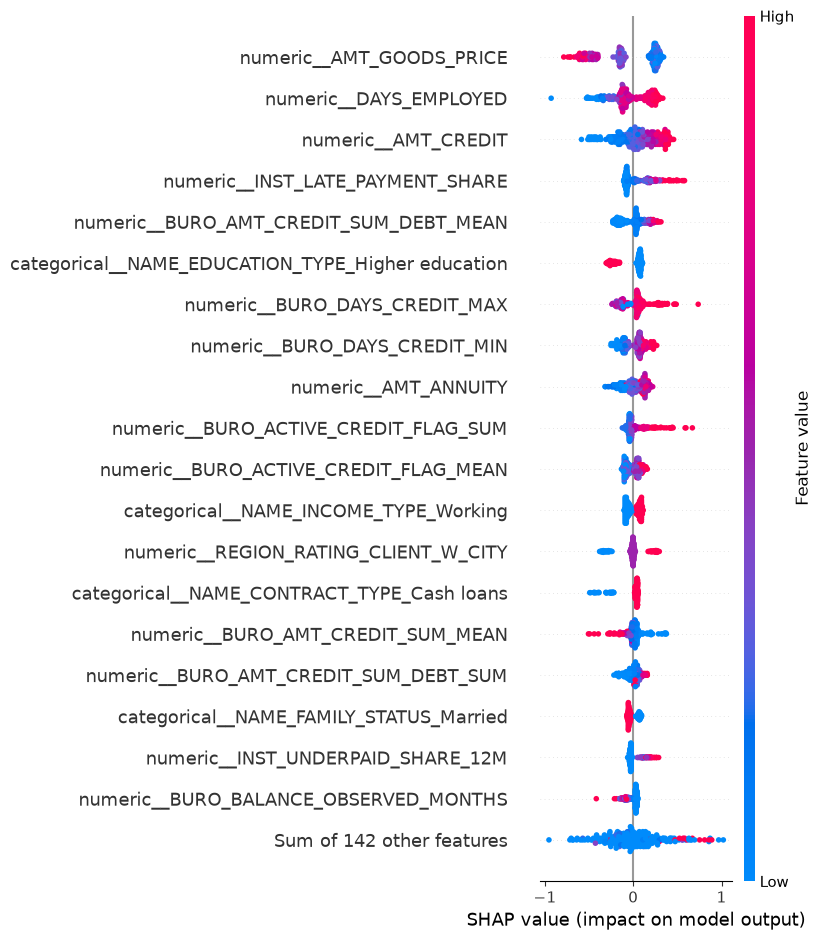

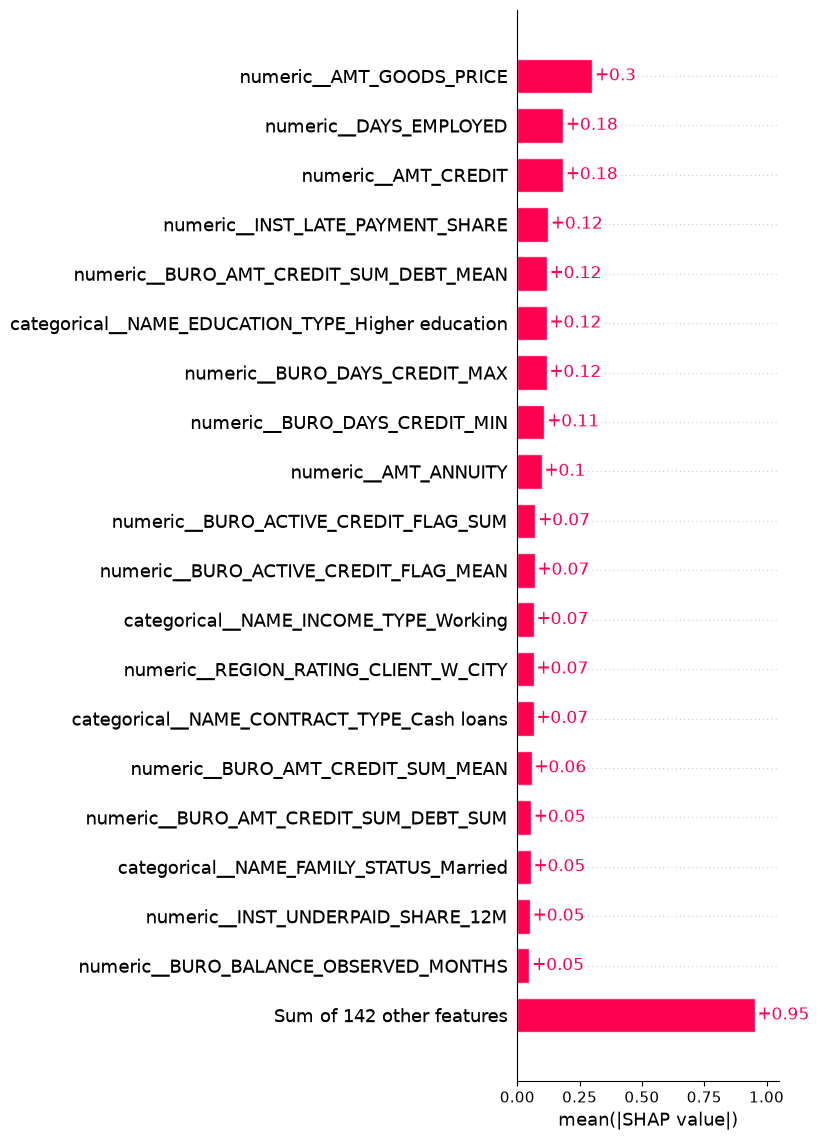

SHAP global plots saved.


In [20]:
import shap

selected_model_name = group_b_cv.sort_values(
    "PR_AUC_mean", ascending=False
).iloc[0]["model"]

best_group_b_pipeline = tuned_models[
    ("B_conventional_plus_behavioural", selected_model_name)
]

best_group_b_pipeline.fit(
    train_core[GROUP_B_FULL],
    y_core,
)

preprocessor = best_group_b_pipeline.named_steps["preprocess"]
estimator = best_group_b_pipeline.named_steps["model"]

# Use a manageable sample for explainability.
background_rows = min(200, len(train_core))
explain_rows = min(300, len(calibration_validation))

X_background = train_core[GROUP_B_FULL].sample(
    n=background_rows,
    random_state=RANDOM_STATE,
)

X_explain = calibration_validation[GROUP_B_FULL].sample(
    n=explain_rows,
    random_state=RANDOM_STATE,
)

X_background_transformed = preprocessor.transform(X_background)
X_explain_transformed = preprocessor.transform(X_explain)

feature_names = preprocessor.get_feature_names_out()

# Sparse matrices can be retained for memory efficiency; convert only
# the small explainability samples when necessary.
if hasattr(X_background_transformed, "toarray"):
    X_background_shap = X_background_transformed.toarray()
else:
    X_background_shap = np.asarray(X_background_transformed)

if hasattr(X_explain_transformed, "toarray"):
    X_explain_shap = X_explain_transformed.toarray()
else:
    X_explain_shap = np.asarray(X_explain_transformed)

explainer = shap.Explainer(
    estimator,
    X_background_shap,
    feature_names=feature_names,
)

shap_values = explainer(X_explain_shap)

# For binary classification, select the positive class when a class
# dimension is present.
if len(shap_values.values.shape) == 3:
    positive_class_values = shap_values.values[:, :, 1]
    positive_class_base = (
        shap_values.base_values[:, 1]
        if np.asarray(shap_values.base_values).ndim == 2
        else shap_values.base_values
    )

    shap_explanation = shap.Explanation(
        values=positive_class_values,
        base_values=positive_class_base,
        data=X_explain_shap,
        feature_names=feature_names,
    )
else:
    shap_explanation = shap_values

shap.plots.beeswarm(
    shap_explanation,
    max_display=20,
    show=False,
)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "shap_global_beeswarm.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

shap.plots.bar(
    shap_explanation,
    max_display=20,
    show=False,
)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "shap_global_importance.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("SHAP global plots saved.")

In [23]:
SECONDARY_DIR = DATA_DIR / "give_me_some_credit"

secondary_candidates = list(SECONDARY_DIR.rglob("*.csv"))
if not secondary_candidates:
    raise FileNotFoundError(
        "No CSV found in data/give_me_some_credit/. "
        "Place the extracted Give Me Some Credit training CSV there."
    )

# Prefer the standard training filename if multiple CSVs are present.
preferred = [
    p for p in secondary_candidates
    if p.name.lower().startswith("cs-training")
]
secondary_path = preferred[0] if preferred else secondary_candidates[0]

secondary = pd.read_csv(secondary_path, low_memory=False)

# The Kaggle training CSV commonly includes an exported row-index column.
unnamed_columns = [
    c for c in secondary.columns
    if c.lower().startswith("unnamed:")
]
secondary = secondary.drop(columns=unnamed_columns)

SECONDARY_TARGET = "SeriousDlqin2yrs"

if SECONDARY_TARGET not in secondary.columns:
    raise ValueError(
        f"Target {SECONDARY_TARGET} not found. "
        f"Found columns: {secondary.columns.tolist()}"
    )

if secondary[SECONDARY_TARGET].isna().any():
    raise ValueError(
        "Secondary target contains missing values. "
        "Investigate the dataset before replication."
    )

if not set(secondary[SECONDARY_TARGET].unique()).issubset({0, 1}):
    raise ValueError("Secondary target must contain only 0 and 1.")

print("Secondary dataset:", secondary_path)
print("Shape:", secondary.shape)
display(secondary.head())
display(
    secondary[SECONDARY_TARGET]
    .value_counts(normalize=True)
    .rename("proportion")
    .to_frame()
)

secondary_group_a_candidates = [
    "MonthlyIncome",
    "DebtRatio",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents",
]

secondary_behaviour_candidates = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

secondary_group_a = [
    c for c in secondary_group_a_candidates
    if c in secondary.columns
]
secondary_behaviour = [
    c for c in secondary_behaviour_candidates
    if c in secondary.columns
]

if not secondary_group_a or not secondary_behaviour:
    raise ValueError(
        "The secondary dataset is missing expected conventional "
        "or behavioural features. Check the actual CSV schema."
    )

secondary_group_b = secondary_group_a + secondary_behaviour

secondary_train, secondary_test = train_test_split(
    secondary,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=secondary[SECONDARY_TARGET],
)

secondary_y_train = secondary_train[SECONDARY_TARGET].astype(int)
secondary_y_test = secondary_test[SECONDARY_TARGET].astype(int)

secondary_results = []

for group_name, feature_columns in {
    "A_conventional": secondary_group_a,
    "B_conventional_plus_behavioural": secondary_group_b,
}.items():

    X_train_secondary = secondary_train[feature_columns]
    X_test_secondary = secondary_test[feature_columns]

    for model_name in MODEL_NAMES:
        print("Replication:", group_name, "|", model_name)

        # The same algorithm families and preprocessing strategy are used.
        # Parameters are fixed here; the primary tuning results are not
        # transferred as if the datasets had identical feature spaces.
        model = make_model_pipeline(
            model_name,
            X_train_secondary,
        )

        model.fit(X_train_secondary, secondary_y_train)
        probability = model.predict_proba(
            X_test_secondary
        )[:, 1]

        secondary_results.append({
            "feature_group": group_name,
            "model": model_name,
            "PR_AUC": average_precision_score(
                secondary_y_test, probability
            ),
            "ROC_AUC": roc_auc_score(
                secondary_y_test, probability
            ),
        })

secondary_results_df = pd.DataFrame(secondary_results)
display(
    secondary_results_df.sort_values(
        "PR_AUC", ascending=False
    )
)

secondary_results_df.to_csv(
    RESULTS_DIR / "secondary_dataset_replication.csv",
    index=False,
)

Secondary dataset: c:\mini_project\data\give_me_some_credit\cs-training.csv
Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


,proportion
SeriousDlqin2yrs,
0,0.93316
1,0.06684


Replication: A_conventional | Logistic Regression
Replication: A_conventional | Random Forest
Replication: A_conventional | XGBoost
Replication: B_conventional_plus_behavioural | Logistic Regression
Replication: B_conventional_plus_behavioural | Random Forest
Replication: B_conventional_plus_behavioural | XGBoost


,feature_group,model,PR_AUC,ROC_AUC
5,B_conventional_plus_behavioural,XGBoost,0.359975,0.847744
4,B_conventional_plus_behavioural,Random Forest,0.321294,0.831003
3,B_conventional_plus_behavioural,Logistic Regression,0.319980,0.785825
2,A_conventional,XGBoost,0.129363,0.671934
1,A_conventional,Random Forest,0.101686,0.622083
0,A_conventional,Logistic Regression,0.095696,0.582964


In [24]:
import joblib

# Select the final Group B model using repeated-CV PR-AUC, not test results.
selected_model_name = (
    group_b_cv.sort_values("PR_AUC_mean", ascending=False)
    .iloc[0]["model"]
)

selected_group_b_key = (
    "B_conventional_plus_behavioural",
    selected_model_name,
)

selected_group_a_model_name = (
    cv_summary[
        cv_summary["feature_group"] == "A_conventional"
    ]
    .sort_values("PR_AUC_mean", ascending=False)
    .iloc[0]["model"]
)

selected_group_a_key = (
    "A_conventional",
    selected_group_a_model_name,
)

# Save calibrated models, which include preprocessing and estimators.
joblib.dump(
    calibrated_models[selected_group_b_key],
    ARTIFACT_DIR / "best_group_b_calibrated_model.joblib",
)

joblib.dump(
    calibrated_models[selected_group_a_key],
    ARTIFACT_DIR / "best_group_a_calibrated_model.joblib",
)

# Save all six models so the dashboard can show the full comparison.
joblib.dump(
    calibrated_models,
    ARTIFACT_DIR / "all_calibrated_models.joblib",
)

model_metadata = {
    "project": "FinResilience AI",
    "target_column": TARGET_COL,
    "positive_class": 1,
    "primary_metric": "PR-AUC",
    "random_state": RANDOM_STATE,
    "cv_folds": N_SPLITS,
    "cv_repeats": N_REPEATS,
    "selected_group_a_model": selected_group_a_model_name,
    "selected_group_b_model": selected_model_name,
    "group_a_features": GROUP_A,
    "behavioural_features_added": BEHAVIOURAL_FEATURES,
    "group_b_features": GROUP_B_FULL,
    "group_a_threshold": selected_thresholds[selected_group_a_key],
    "group_b_threshold": selected_thresholds[selected_group_b_key],
    "threshold_selection": (
        "F1 maximization on the training-only calibration-validation subset"
    ),
    "test_set_status": (
        "Final evaluation completed; do not use for further model selection"
    ),
    "limitations": [
        "Linked-table chronology must be verified for application-time availability.",
        "SHAP explains the underlying model, not calibrated probabilities.",
        "Give Me Some Credit uses a distinct target and feature space.",
        "Predictive associations are not causal effects.",
    ],
}

with open(
    ARTIFACT_DIR / "model_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(model_metadata, file, indent=2)

print("Saved final artifacts:")
print(ARTIFACT_DIR / "best_group_a_calibrated_model.joblib")
print(ARTIFACT_DIR / "best_group_b_calibrated_model.joblib")
print(ARTIFACT_DIR / "all_calibrated_models.joblib")
print(ARTIFACT_DIR / "model_metadata.json")

print("\nSelected Group A model:", selected_group_a_model_name)
print("Selected Group B model:", selected_model_name)

Saved final artifacts:
c:\mini_project\artifacts\best_group_a_calibrated_model.joblib
c:\mini_project\artifacts\best_group_b_calibrated_model.joblib
c:\mini_project\artifacts\all_calibrated_models.joblib
c:\mini_project\artifacts\model_metadata.json

Selected Group A model: XGBoost
Selected Group B model: XGBoost


In [25]:
best_a_cv = cv_summary[
    cv_summary["feature_group"] == "A_conventional"
].sort_values("PR_AUC_mean", ascending=False).iloc[0]

best_b_cv = cv_summary[
    cv_summary["feature_group"] == "B_conventional_plus_behavioural"
].sort_values("PR_AUC_mean", ascending=False).iloc[0]

summary = {
    "primary_dataset": "Home Credit Default Risk",
    "target": "TARGET",
    "primary_metric": "PR-AUC",
    "best_group_a_model_by_cv": str(best_a_cv["model"]),
    "best_group_a_cv_PR_AUC": float(best_a_cv["PR_AUC_mean"]),
    "best_group_b_model_by_cv": str(best_b_cv["model"]),
    "best_group_b_cv_PR_AUC": float(best_b_cv["PR_AUC_mean"]),
    "best_group_b_minus_best_group_a_cv_PR_AUC": float(
        best_b_cv["PR_AUC_mean"] - best_a_cv["PR_AUC_mean"]
    ),
    "locked_test_evaluation_completed": True,
    "secondary_replication_completed": True,
}

with open(
    RESULTS_DIR / "research_summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(summary, file, indent=2)

display(pd.DataFrame([summary]))

print("\nNotebook 2 workflow completed.")
print("Review all result tables and warnings before writing conclusions.")
print("Do not claim Group B is better unless the results support it.")

,primary_dataset,target,primary_metric,best_group_a_model_by_cv,best_group_a_cv_PR_AUC,best_group_b_model_by_cv,best_group_b_cv_PR_AUC,best_group_b_minus_best_group_a_cv_PR_AUC,locked_test_evaluation_completed,secondary_replication_completed
0,Home Credit Default Risk,TARGET,PR-AUC,XGBoost,0.161545,XGBoost,0.203404,0.04186,True,True



Notebook 2 workflow completed.
Review all result tables and warnings before writing conclusions.
Do not claim Group B is better unless the results support it.
